In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import python_anesthesia_simulator as pas

In [10]:
# Load data
data = pd.read_csv('data/database.csv')
data.rename(columns={'BIS_Eleveld': 'BIS_sim'}, inplace=True)
data['TPR'] = (data['MAP'] / (data['HR'] * data['SV'])).clip(0, 0.04)
data['TPR_sim'] = (data['MAP_sim'] / (data['HR_sim'] * data['SV_sim'])).clip(0, 0.04)

In [11]:
available_bis_model = [
    'Eleveld',
    'Bouillon',
    'Vanluchene',
    'Fuentes',
    'Kern',
    'Mertens',
    'Johnson',
    'Yumuk',
    ]
for model in available_bis_model:
    if model=='Eleveld':
        bis = []
        for caseid, data_case in data.groupby('caseid'):
            bis_model = pas.BIS_model(hill_model=model, age=data_case['age'].iloc[0])
            bis_case = bis_model.compute_bis(data_case['Ce_prop'].values, data_case['Ce_remi'].values)
            bis+=list(bis_case)
    else:
        bis_model = pas.BIS_model(hill_model=model)
        bis = bis_model.compute_bis(data['Ce_prop'].values, data['Ce_remi'].values)
    data.insert(0, f"BIS_{model}", bis)

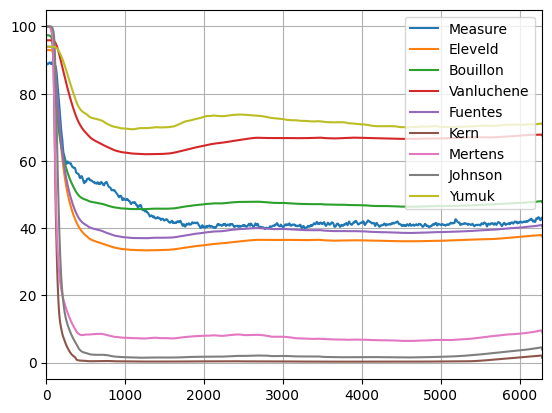

In [22]:
min_case_duration = data.groupby('caseid')['Time'].max().min()

data['Time'] = data.groupby('caseid')['Time'].transform(lambda x: x - x.min())
intub_median = np.median(data['intubation_time'].unique())
opstart_median = np.median(data['opstart'].unique())
bis_mean = data.groupby("Time")["BIS"].mean()
bis_std = data.groupby("Time")["BIS"].std()
x = bis_mean.index
plt.plot(x, bis_mean, label='Measure')
for model in available_bis_model:
    bis_mean = data.groupby("Time")[f"BIS_{model}"].mean().values
    plt.plot(x, bis_mean, label=model)

plt.grid()
plt.legend(prop={'size': 10}, loc=1)
plt.xlim([0,min_case_duration])
plt.show()

In [28]:
mdpe_model = {}
mdape_model = {}
for model in available_bis_model:
    mdpe_model_list = []
    mdape_model_list = []
    length_list = []

    for caseid, data_case in data.groupby('caseid'):
        PE = 100 * ((data_case['BIS'] - data_case[f"BIS_{model}"])/data_case['BIS']).values
        MDPE_case = np.median(PE)
        MDAPE_case = np.median(np.abs(PE))
        var_mdpe_case = np.var(PE)
        mdpe_model_list.append(MDPE_case)
        mdape_model_list.append(MDAPE_case)
        length_list.append(len(PE))
    
    MDPE_model = np.sum(np.multiply(mdpe_model_list,length_list)) / np.sum(length_list)
    MDAPE_model = np.sum(np.multiply(mdape_model_list,length_list)) / np.sum(length_list)
    mdpe_model[model] = MDPE_model
    mdape_model[model] = MDAPE_model
print(mdpe_model)
print(mdape_model)

{'Eleveld': np.float64(9.514442258672146), 'Bouillon': np.float64(-14.31218827750208), 'Vanluchene': np.float64(-61.672168634333204), 'Fuentes': np.float64(3.1126145673617343), 'Kern': np.float64(99.45201392155963), 'Mertens': np.float64(83.5484720424138), 'Johnson': np.float64(96.47693618552772), 'Yumuk': np.float64(-71.75765937528826)}
{'Eleveld': np.float64(22.53076719789962), 'Bouillon': np.float64(21.412248555588913), 'Vanluchene': np.float64(62.28460685969044), 'Fuentes': np.float64(19.118945480895952), 'Kern': np.float64(99.45443377935366), 'Mertens': np.float64(83.69583631250569), 'Johnson': np.float64(96.50590301458938), 'Yumuk': np.float64(73.41057799468118)}


In [32]:
data.caseid.nunique()

134